# Titanic Survival Analysis

An exploratory analysis of the Titanic passenger dataset (891 passengers, 12 original columns).
**Question: which factors were linked to survival?**

**Tools:** Python (pandas, matplotlib, seaborn) in Jupyter, with Excel used to cross-check the results.

**Key columns:** `Survived` (1 = survived, 0 = died), `Pclass` (ticket class, 1 = highest), `Sex`, `Age`,
`SibSp` (siblings/spouses aboard), `Parch` (parents/children aboard), `Fare`, `Cabin`, `Embarked` (port of boarding).

---

## What each section of this notebook does

**Setup (cell 1).** Imports the libraries and sets a clean chart style. Charts are saved to an `images/` folder.

**1. Load the data (cell 2).** Reads the CSV into a pandas DataFrame, a table of rows and columns like an Excel sheet.

**2. Inspect (cell 3).** `.shape` gives (rows, columns): 891 passengers, 12 columns. `.info()` lists each column's type and how many values are present.

**3. Find missing values (cell 4).** Empty cells show up as `NaN`. Charts and models can't use them, so we count them first.

| Column | Missing | Share |
|---|---|---|
| Age | 177 | 19.9% |
| Cabin | 687 | 77.1% |
| Embarked | 2 | 0.2% |

**4. Clean and create columns (cell 5).** All changes are made on a copy called `clean`, so the original `df` stays untouched.

- **Age** is filled with the median (the middle value, which extreme ages don't pull around).
- **Embarked** is filled with the mode (the most common port, Southampton).
- **Cabin** is too empty to fill, so `HasCabin` records whether a cabin was listed (1) or not (0).

| New column | How it is made | Meaning |
|---|---|---|
| `FamilySize` | `SibSp + Parch + 1` | People in the family group, including the passenger |
| `IsAlone` | `FamilySize == 1` | 1 if travelling alone |
| `Outcome` | `Survived` mapped to text | "Died" / "Survived", for chart legends |
| `AgeGroup` | `pd.cut` on `Age` | Child (0-12), Teen, Adult, Middle, Senior |
| `Title` | Regular expression on `Name` | Mr, Mrs, Miss, Master |

"Mlle" and "Ms" are merged into Miss, and "Mme" into Mrs. All other titles (Dr, Rev, Col, ...) have only a few passengers each, so they are grouped as **Rare**.

**5. Save the cleaned data (cell 6).** Writes `titanic_clean.csv` (891 rows, 18 columns), so the same steps can be compared in Excel.

**6. Survival rates (cell 7).** `Survived` is 1 or 0, so its mean is the survival rate. `groupby` splits passengers into groups and calculates the rate in each.

**7. Visualisations (cells 8-13).** Survival by sex, by class, by sex and class together (heatmap), the age distribution, survival by age group, and survival by family size.

---

## Findings

- Overall survival was **38.4%**.
- **Sex:** women survived at **74.2%**, men at **18.9%**.
- **Class:** **63.0%** (1st), **47.3%** (2nd), **24.2%** (3rd).
- **The two compound:** 1st-class women survived at about 97%, 3rd-class men at about 14%, roughly a seven-fold gap.
- **Children (0-12)** had the highest age-group survival, about **58%**.
- **Family size:** people travelling alone survived at about 30%, families of 2-4 did better (up to about 72% for 4).

## Limitations

- These are associations in the data, not proof of cause.
- 177 ages (20%) were filled with one median value. This causes the artificial spike at age 28 in the age histogram.
- Cabin was too incomplete to analyse (77% missing).
- The Child group is small (around 70 passengers), and family sizes 8 and 11 have only 6 and 7 passengers, so those figures are unreliable.
- The data covers 891 passengers, not everyone aboard.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print(df.shape)
df.info()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
missing = df.isna().sum()
percent = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": percent})[missing > 0]

,missing,percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


In [5]:
clean = df.copy()

# Fill missing values
clean["Age"] = clean["Age"].fillna(clean["Age"].median())
clean["Embarked"] = clean["Embarked"].fillna(clean["Embarked"].mode()[0])
clean["HasCabin"] = clean["Cabin"].notna().astype(int)

# New columns
clean["FamilySize"] = clean["SibSp"] + clean["Parch"] + 1
clean["IsAlone"] = (clean["FamilySize"] == 1).astype(int)
clean["Outcome"] = clean["Survived"].map({0: "Died", 1: "Survived"})
clean["AgeGroup"] = pd.cut(
    clean["Age"],
    bins=[0, 12, 18, 35, 60, 120],
    labels=["Child", "Teen", "Adult", "Middle", "Senior"],
)

# Titles
clean["Title"] = clean["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
clean["Title"] = clean["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
main_titles = ["Mr", "Mrs", "Miss", "Master"]
clean["Title"] = clean["Title"].where(clean["Title"].isin(main_titles), "Rare")

print(clean.isna().sum()[lambda s: s > 0])   # only Cabin should remain
clean["Title"].value_counts()

Cabin    687
dtype: int64


Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

In [6]:
clean.to_csv("titanic_clean.csv", index=False)
print("saved", clean.shape)

saved (891, 18)


In [7]:
print("Overall:", round(clean["Survived"].mean() * 100, 1), "%")
print()
print(clean.groupby("Sex")["Survived"].mean().mul(100).round(1))
print()
print(clean.groupby("Pclass")["Survived"].mean().mul(100).round(1))

Overall: 38.4 %

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


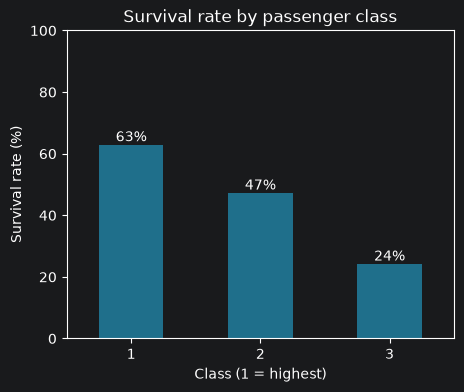

In [8]:
rate = clean.groupby("Pclass")["Survived"].mean() * 100

ax = rate.plot(kind="bar", color="#1F6F8B", figsize=(5, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f%%")
ax.set_title("Survival rate by passenger class")
ax.set_xlabel("Class (1 = highest)")
ax.set_ylabel("Survival rate (%)")
ax.set_ylim(0, 100)

plt.savefig("images/survival_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

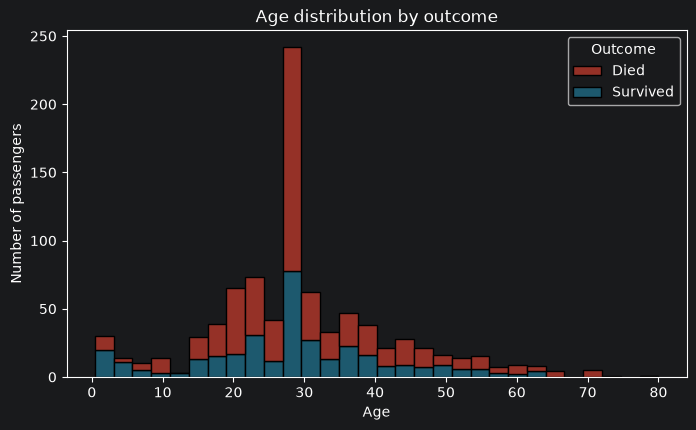

In [9]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=clean, x="Age", hue="Outcome", bins=30, multiple="stack",
             palette={"Died": "#C0392B", "Survived": "#1F6F8B"})
plt.title("Age distribution by outcome")
plt.xlabel("Age")
plt.ylabel("Number of passengers")

plt.savefig("images/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions
1. **Sex** was the strongest factor: 74% of women survived vs 19% of men.
2. **Class** mattered: 63% of 1st class survived vs 24% of 3rd class.
3. The two effects **compound**: 1st-class women survived at 97%, 3rd-class men at 14%.
4. **Children** and **small families** had better odds than adults travelling alone.

**Limitations**
- These are associations in the data, not proof of cause.
- 20% of ages were estimated with the median, and Cabin was too incomplete to analyse.
- The data covers 891 passengers, not everyone aboard.